<a href="https://colab.research.google.com/github/documento69/PY/blob/Feature-2/Copy_of_1_NICER_LinearRegression_Sklearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression with scikit-learn

This notebook is designed for a hands-on workshop on building and interpreting a linear regression model with Python.

By the end of the session, participants should be able to:
- identify the target variable and input features,
- inspect a dataset before modeling,
- split data into training and testing sets,
- train a baseline linear regression model,
- evaluate predictions using MAE, RMSE, and R-squared,
- interpret model coefficients carefully,
- improve the model by adding more useful features.

Workshop rhythm:
1. Run a section.
2. Pause at each checkpoint.
3. Discuss what changed and why it matters.


## 1. Setup

Run this section first. If a package is missing in a fresh environment, uncomment the install lines once, run them, then restart the kernel.


In [ ]:
# Uncomment these only if your environment does not have the packages yet.
!pip install numpy pandas matplotlib seaborn scikit-learn


In [5]:
from pathlib import Path

import numpy as np # for arrays, lists
import pandas as pd # for reading csv files
import matplotlib.pyplot as plt # for visualizations graphs
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
RANDOM_STATE = 42


### Helper functions

These functions keep repeated evaluation and plotting code short. They also make it easier to compare models later in the workshop.


In [1]:
def evaluate_regression(y_true, y_pred, model_name):
    """Return common regression metrics as a one-row dictionary."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R-squared": r2,
    }


def print_metric_summary(metrics):
    print(f"MAE:       {metrics['MAE']:,.2f}")
    print(f"RMSE:      {metrics['RMSE']:,.2f}")
    print(f"R-squared: {metrics['R-squared']:.3f}")


def plot_actual_vs_predicted(y_true, y_pred, title):
    plt.figure(figsize=(7, 6))
    sns.scatterplot(x=y_true, y=y_pred, alpha=0.75)

    min_value = min(y_true.min(), y_pred.min())
    max_value = max(y_true.max(), y_pred.max())
    plt.plot([min_value, max_value], [min_value, max_value], color="red", linestyle="--")

    plt.xlabel("Actual Price")
    plt.ylabel("Predicted Price")
    plt.title(title)
    plt.show()


def plot_residuals(y_true, y_pred, title):
    residuals = y_true - y_pred

    plt.figure(figsize=(7, 5))
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.75)
    plt.axhline(0, color="red", linestyle="--")
    plt.xlabel("Predicted Price")
    plt.ylabel("Residual (Actual - Predicted)")
    plt.title(title)
    plt.show()


## 2. Load the Dataset

We will use `Housing.csv`, which contains house prices and property characteristics.

In supervised learning language:
- the **target** is the value we want to predict,
- the **features** are the inputs the model uses to make that prediction.


In [6]:
DATA_PATH = Path("Housing.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Housing.csv was not found in this notebook folder. "
        "Place the file beside the notebook, then rerun this cell."
    )

data = pd.read_csv(DATA_PATH)
data.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [7]:
print(f"Rows: {data.shape[0]:,}")
print(f"Columns: {data.shape[1]:,}")
print(data.columns.tolist())


Rows: 545
Columns: 13
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


### Data dictionary

Use this table to orient the group before modeling. Ask participants which columns are likely to be useful predictors and why.


In [8]:
data_dictionary = pd.DataFrame({
    "column": data.columns,
    "meaning": [
        "Selling price of the house",
        "House area",
        "Number of bedrooms",
        "Number of bathrooms",
        "Number of stories",
        "Whether the house is on a main road",
        "Whether the house has a guest room",
        "Whether the house has a basement",
        "Whether the house has hot water heating",
        "Whether the house has air conditioning",
        "Number of parking spaces",
        "Whether the house is in a preferred area",
        "Furnishing status",
    ],
})

data_dictionary


,column,meaning
0,price,Selling price of the house
1,area,House area
2,bedrooms,Number of bedrooms
3,bathrooms,Number of bathrooms
4,stories,Number of stories
5,mainroad,Whether the house is on a main road
6,guestroom,Whether the house has a guest room
7,basement,Whether the house has a basement
8,hotwaterheating,Whether the house has hot water heating
9,airconditioning,Whether the house has air conditioning


## 3. Quick Data Understanding

Before training a model, inspect the data. This prevents avoidable mistakes such as using the wrong target, ignoring missing values, or accidentally treating text as numbers.


In [9]:
# Data types and missing values in one compact view.
column_summary = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_values": data.isna().sum(),
    "missing_percent": data.isna().mean() * 100,
    "unique_values": data.nunique(),
})

column_summary


,dtype,missing_values,missing_percent,unique_values
price,int64,0,0.00,219
area,int64,0,0.00,284
bedrooms,int64,0,0.00,6
bathrooms,int64,0,0.00,4
stories,int64,0,0.00,4
mainroad,object,0,0.00,2
guestroom,object,0,0.00,2
basement,object,0,0.00,2
hotwaterheating,object,0,0.00,2
airconditioning,object,0,0.00,2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Summary statistics for numeric columns.
data.describe()


,price,area,bedrooms,bathrooms,stories,parking
count,545.00,545.00,545.00,545.00,545.00,545.00
mean,"4,766,729.25","5,150.54",2.97,1.29,1.81,0.69
std,"1,870,439.62","2,170.14",0.74,0.50,0.87,0.86
min,"1,750,000.00","1,650.00",1.00,1.00,1.00,0.00
25%,"3,430,000.00","3,600.00",2.00,1.00,1.00,0.00
50%,"4,340,000.00","4,600.00",3.00,1.00,2.00,0.00
75%,"5,740,000.00","6,360.00",3.00,2.00,2.00,1.00
max,"13,300,000.00","16,200.00",6.00,4.00,4.00,3.00


### Checkpoint 1

Discuss these questions before moving on:
- What is the target variable?
- Which columns are numeric?
- Which columns are categorical?
- Are there missing values we need to handle?


In [11]:
insull().sum()

NameError: name 'insull' is not defined

## 4. Explore Relationships Visually

A linear regression model works best when the relationship between a feature and the target is roughly linear. Plots help us see whether that assumption is reasonable.


NameError: name 'data' is not defined

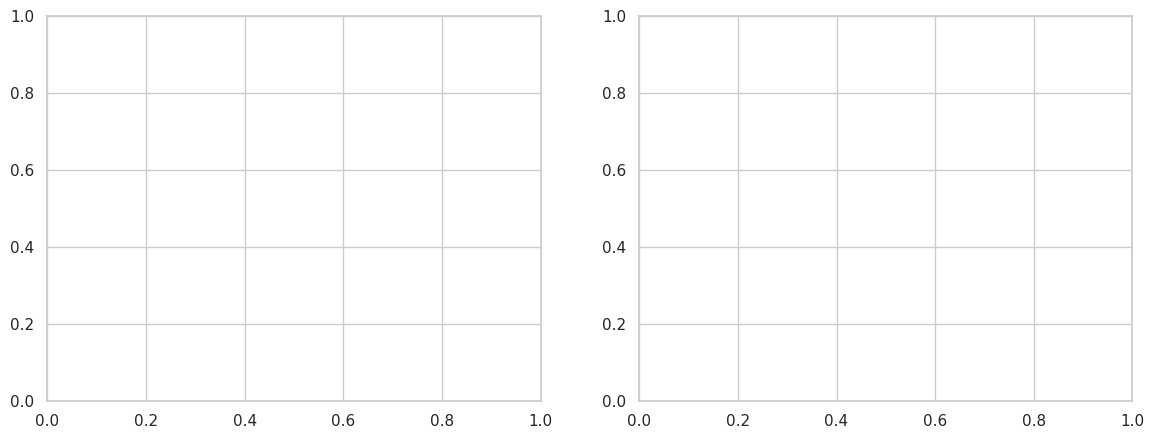

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data["price"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of House Prices")
axes[0].set_xlabel("Price")

sns.scatterplot(data=data, x="area", y="price", hue="airconditioning", alpha=0.75, ax=axes[1])
axes[1].set_title("Price vs Area")
axes[1].set_xlabel("Area")
axes[1].set_ylabel("Price")

plt.tight_layout()
plt.show()


In [ ]:
numeric_columns = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]

plt.figure(figsize=(8, 5))
sns.heatmap(data[numeric_columns].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap for Numeric Columns")
plt.show()


NameError: name 'data' is not defined

<Figure size 800x500 with 0 Axes>

### Checkpoint 2

Ask the group:
- Which numeric feature has the strongest positive correlation with price?
- Does correlation prove that one variable causes another?
- What information might be missing from the numeric-only view?


## 5. Build a Simple Baseline Model

Start with one feature: `area`. A baseline gives us a simple comparison point before adding more features.

The model will learn an equation like:

`predicted_price = intercept + coefficient * area`


In [ ]:
target = "price"
simple_features = ["area"]

X_simple = data[simple_features]
y = data[target]

X_train_simple, X_test_simple, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print("Training rows:", X_train_simple.shape[0])
print("Testing rows:", X_test_simple.shape[0])


In [ ]:
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)

simple_intercept = simple_model.intercept_
simple_area_coefficient = simple_model.coef_[0]

print(f"Intercept: {simple_intercept:,.2f}")
print(f"Area coefficient: {simple_area_coefficient:,.2f}")
print()
print("Interpretation:")
print(f"For each additional unit of area, the model adds about {simple_area_coefficient:,.2f} to the predicted price.")


In [ ]:
simple_predictions = simple_model.predict(X_test_simple)
simple_metrics = evaluate_regression(y_test, simple_predictions, "Area-only baseline")
print_metric_summary(simple_metrics)


In [ ]:
comparison_simple = pd.DataFrame({
    "actual_price": y_test.values,
    "predicted_price": simple_predictions,
    "error": y_test.values - simple_predictions,
})

comparison_simple.head(10)


In [ ]:
plot_actual_vs_predicted(
    y_test,
    simple_predictions,
    "Area-only Baseline: Actual vs Predicted Price",
)


### Checkpoint 3

Discuss:
- What does the area coefficient mean?
- Is the intercept meaningful in the real world?
- What kinds of homes might this one-feature model predict poorly?


## 6. Add More Numeric Features

A house price is unlikely to depend on area alone. Next we add more numeric features:
- `area`
- `bedrooms`
- `bathrooms`
- `stories`
- `parking`

We will use a `Pipeline` with `StandardScaler` and `LinearRegression`. Scaling is not required for ordinary linear regression predictions, but it helps compare coefficient sizes because the features are placed on a similar scale.


In [ ]:
numeric_features = ["area", "bedrooms", "bathrooms", "stories", "parking"]

X_numeric = data[numeric_features]

X_train_numeric, X_test_numeric, y_train, y_test = train_test_split(
    X_numeric,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

numeric_pipeline = Pipeline(steps=[
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])

numeric_pipeline.fit(X_train_numeric, y_train)
numeric_predictions = numeric_pipeline.predict(X_test_numeric)

numeric_metrics = evaluate_regression(y_test, numeric_predictions, "Numeric features")
print_metric_summary(numeric_metrics)


NameError: name 'data' is not defined

In [ ]:
numeric_coefficients = pd.DataFrame({
    "feature": numeric_features,
    "coefficient_after_scaling": numeric_pipeline.named_steps["model"].coef_,
})

numeric_coefficients["absolute_coefficient"] = numeric_coefficients["coefficient_after_scaling"].abs()
numeric_coefficients.sort_values("absolute_coefficient", ascending=False)


In [ ]:
model_comparison = pd.DataFrame([simple_metrics, numeric_metrics]).set_index("model")
model_comparison


In [ ]:
plot_actual_vs_predicted(
    y_test,
    numeric_predictions,
    "Numeric Feature Model: Actual vs Predicted Price",
)

plot_residuals(
    y_test,
    numeric_predictions,
    "Numeric Feature Model: Residual Plot",
)


### Checkpoint 4

Discuss:
- Did adding more numeric features improve the model?
- Which metric changed the most?
- Which coefficient is largest after scaling?
- Why should we avoid judging a model using only the training data?


## 7. Extension: Add Categorical Features

The dataset has useful categorical columns such as `mainroad`, `airconditioning`, and `furnishingstatus`.

Machine learning models need numbers, so we encode categories using one-hot encoding. The `ColumnTransformer` below applies different preprocessing to numeric and categorical columns inside one pipeline.


In [ ]:
categorical_features = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishingstatus",
]

all_features = numeric_features + categorical_features
X_all = data[all_features]

X_train_all, X_test_all, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

preprocess = ColumnTransformer(transformers=[
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
])

full_pipeline = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LinearRegression()),
])

full_pipeline.fit(X_train_all, y_train)
full_predictions = full_pipeline.predict(X_test_all)

full_metrics = evaluate_regression(y_test, full_predictions, "Numeric + categorical features")
print_metric_summary(full_metrics)


In [ ]:
model_comparison = pd.DataFrame([simple_metrics, numeric_metrics, full_metrics]).set_index("model")
model_comparison


In [ ]:
encoded_feature_names = full_pipeline.named_steps["preprocess"].get_feature_names_out()
full_coefficients = pd.DataFrame({
    "feature": encoded_feature_names,
    "coefficient": full_pipeline.named_steps["model"].coef_,
})

full_coefficients["absolute_coefficient"] = full_coefficients["coefficient"].abs()
full_coefficients.sort_values("absolute_coefficient", ascending=False).head(12)


In [ ]:
plot_actual_vs_predicted(
    y_test,
    full_predictions,
    "Full Feature Model: Actual vs Predicted Price",
)

plot_residuals(
    y_test,
    full_predictions,
    "Full Feature Model: Residual Plot",
)


### Checkpoint 5

Discuss:
- Did categorical features improve the model?
- Which categorical features appear useful?
- What does one-hot encoding do?
- Why is `handle_unknown="ignore"` helpful when predicting on new data?


## 8. Workshop Exercise

Use the cells below for hands-on practice. Change one thing at a time, rerun the model, and compare the metrics.

Suggested experiments:
- remove one numeric feature,
- add only one categorical feature,
- change `test_size` from `0.20` to `0.30`,
- compare results with and without scaling,
- inspect the rows with the largest prediction errors.


In [ ]:
# Exercise: inspect the largest absolute errors from the full model.
error_analysis = X_test_all.copy()
error_analysis["actual_price"] = y_test.values
error_analysis["predicted_price"] = full_predictions
error_analysis["absolute_error"] = (error_analysis["actual_price"] - error_analysis["predicted_price"]).abs()

error_analysis.sort_values("absolute_error", ascending=False).head(10)


In [ ]:
# Exercise template: choose your own feature set and compare the result.
experiment_numeric_features = ["area", "bedrooms", "bathrooms", "stories", "parking"]
experiment_categorical_features = ["airconditioning", "prefarea", "furnishingstatus"]
experiment_features = experiment_numeric_features + experiment_categorical_features

X_experiment = data[experiment_features]
X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
    X_experiment,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

experiment_preprocess = ColumnTransformer(transformers=[
    ("numeric", StandardScaler(), experiment_numeric_features),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), experiment_categorical_features),
])

experiment_pipeline = Pipeline(steps=[
    ("preprocess", experiment_preprocess),
    ("model", LinearRegression()),
])

experiment_pipeline.fit(X_train_exp, y_train_exp)
experiment_predictions = experiment_pipeline.predict(X_test_exp)
experiment_metrics = evaluate_regression(y_test_exp, experiment_predictions, "Experiment")

print_metric_summary(experiment_metrics)


## 9. Wrap-up

Key takeaways:
- Always inspect the data before modeling.
- Train/test split helps estimate performance on unseen data.
- A simple baseline makes improvements easier to judge.
- MAE and RMSE are in the same unit as the target, so they are easier to explain to non-technical audiences.
- R-squared summarizes explained variation, but it should not be the only metric.
- Coefficients are useful, but their interpretation depends on preprocessing and feature design.

Final discussion prompt: What would you try next if this model were going into a real decision-making workflow?
